Chapter 3

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict
import itertools

def get_matching_event(event_condition, sample_space):
    return set([outcome for outcome in sample_space
                if event_condition(outcome)])

def compute_event_probability(event_condition, generic_sample_space):
    event = get_matching_event(event_condition, generic_sample_space)
    if type(generic_sample_space) == type(set()):
        return len(event) / len(generic_sample_space)
    event_size = sum(generic_sample_space[outcome]
                     for outcome in event)
    return event_size / sum(generic_sample_space.values())

1. What is Chapter 3 about? What is its main goal?
It teaches us to simulate random events with NumPy, study the results, and estimate probabilities. The goal is to use simulations when counting every possible outcome is hard.

In [ ]:
# Listing 3.1 – Importing NumPy
import numpy as np

In [ ]:
# Listing 3.2 – Simulating a randomly rolled die
die_roll = np.random.randint(1, 7)
assert 1 <= die_roll <= 6
print(die_roll)

1


2. Why can we now read it and make sense of it?
Chapters 1 and 2 taught us basic probability, sample spaces, and plots. We now know what probabilities and distributions mean, so we can understand simulation results.

3. Why do we simulate coin flips and die rolls?
They are easy random experiments. We can compare the results with probabilities we already know, like 0.5 for heads and 1/6 for one die face.

In [ ]:
# Listing 3.4 – Simulating one fair coin flip
np.random.seed(0)
coin_flip = np.random.randint(0, 2)
print(f"Coin landed on {'heads' if coin_flip == 1 else 'tails'}")

Coin landed on tails


In [ ]:
# Listing 3.5 – Simulating 10 fair coin flips
np.random.seed(0)
def frequency_heads(coin_flip_sequence):
    total_heads = len([head for head in coin_flip_sequence if head == 1])
    return total_heads / len(coin_flip_sequence)

coin_flips = [np.random.randint(0, 2) for _ in range(10)]
freq_heads = frequency_heads(coin_flips)
print(f"Frequency of Heads is {freq_heads}")

Frequency of Heads is 0.8


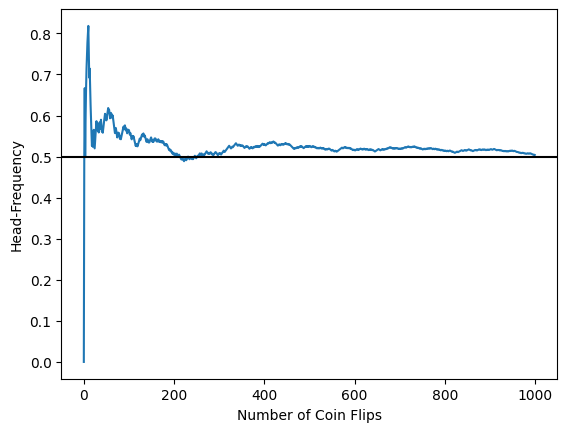

In [ ]:
# Listing 3.6 – Plotting simulated fair coin-flip frequencies (Figure 3.1)
np.random.seed(0)
coin_flips = []
frequencies = []
for _ in range(1000):
    coin_flips.append(np.random.randint(0, 2))
    frequencies.append(frequency_heads(coin_flips))

plt.plot(list(range(1000)), frequencies)
plt.axhline(0.5, color='k')
plt.xlabel('Number of Coin Flips')
plt.ylabel('Head-Frequency')
plt.show()

4. Why are we interested in biased coin flips?
A biased coin has unequal probabilities. It helps us practice estimating an unknown probability from repeated trials, which is useful for a biased deck of cards.


In [ ]:
# Listing 3.7 – Simulating biased coin flips
np.random.seed(0)
print("Let's flip the biased coin once.")
coin_flip = np.random.binomial(1, 0.7)
print(f"Biased coin landed on {'heads' if coin_flip == 1 else 'tails'}.")

print("\nLet's flip the biased coin 10 times.")
number_coin_flips = 10
head_count = np.random.binomial(number_coin_flips, .7)
print((f"{head_count} heads were observed out of "
       f"{number_coin_flips} biased coin flips"))

Let's flip the biased coin once.
Biased coin landed on heads.

Let's flip the biased coin 10 times.
6 heads were observed out of 10 biased coin flips


In [ ]:
# Listing 3.8 – Computing coin-flip-frequency convergence
np.random.seed(0)
head_count = np.random.binomial(1000, 0.7)
frequency = head_count / 1000
print(f"Frequency of Heads is {frequency}")

Frequency of Heads is 0.697


In [ ]:
# Listing 3.9 – Recomputing coin-flip-frequency convergence
np.random.seed(0)
assert np.random.binomial(1000, 0.7) / 1000 == 0.697

for i in range(1, 6):
    head_count = np.random.binomial(1000, 0.7)
    frequency = head_count / 1000
    print(f"Frequency at iteration {i} is {frequency}")
    if frequency == 0.7:
        print("Frequency equals the probability!\n")

Frequency at iteration 1 is 0.69
Frequency at iteration 2 is 0.7
Frequency equals the probability!

Frequency at iteration 3 is 0.707
Frequency at iteration 4 is 0.702
Frequency at iteration 5 is 0.699


5. What is a confidence interval and why is it important?
It is a range of likely values based on our sampled results. A 95% interval tells us which values cover about 95% of the simulated frequency distribution. It helps us see how uncertain our estimate is. Chapter 3 builds this interval using a histogram.
6. Why do we draw histograms? What do we get from them?
A histogram groups results into bins. It shows where values are common, how spread out they are, and where a high-confidence range is located.


In [ ]:
# Listing 3.10 – Computing frequencies with 500 flips per sample
np.random.seed(0)
head_count_list = [np.random.binomial(1000, 0.7) for _ in range(500)]

In [ ]:
# Listing 3.11 – Optimizing the coin-flip-frequency computation
np.random.seed(0)
head_count_array = np.random.binomial(1000, 0.7, 500)

In [ ]:
# Listing 3.12 – Converting a NumPy array to a Python list
assert head_count_array.tolist() == head_count_list

In [ ]:
# Listing 3.13 – Converting a Python list to a NumPy array
new_array = np.array(head_count_list)
assert np.array_equal(new_array, head_count_array) == True

In [ ]:
# Listing 3.14 – Computing frequencies using NumPy
frequency_array = head_count_array / 1000
assert frequency_array.tolist() == [head_count / 1000
                                    for head_count in head_count_list]
assert frequency_array.tolist() == list(map(lambda x: x / 1000,
                                        head_count_list))

In [ ]:
# Listing 3.15 – Printing a NumPy frequency array
print(frequency_array[:20])

[0.697 0.69  0.7   0.707 0.702 0.699 0.723 0.67  0.702 0.713 0.721 0.689
 0.711 0.697 0.717 0.691 0.731 0.697 0.722 0.728]


In [ ]:
# Listing 3.16 – Finding the largest and smallest frequency values
min_freq = frequency_array.min()
max_freq = frequency_array.max()
print(f"Minimum frequency observed: {min_freq}")
print(f"Maximum frequency observed: {max_freq}")
print(f"Difference across frequency range: {max_freq - min_freq}")

Minimum frequency observed: 0.656
Maximum frequency observed: 0.733
Difference across frequency range: 0.07699999999999996


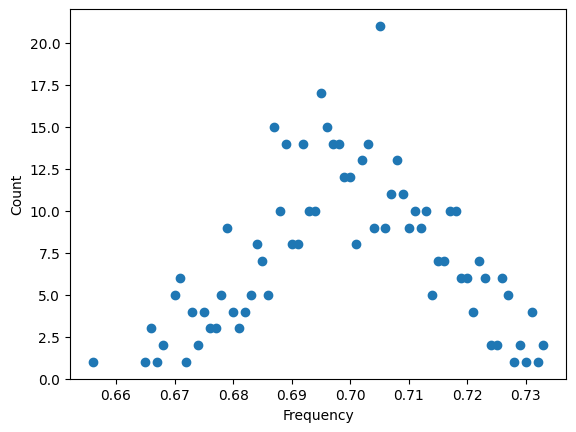

In [ ]:
# Listing 3.17 – Plotting measured frequencies (Figure 3.2)
frequency_counts = defaultdict(int)
for frequency in frequency_array:
    frequency_counts[frequency] += 1

frequencies = list(frequency_counts.keys())
counts = [frequency_counts[freq] for freq in frequencies]
plt.scatter(frequencies, counts)
plt.xlabel('Frequency')
plt.ylabel('Count')
plt.show()

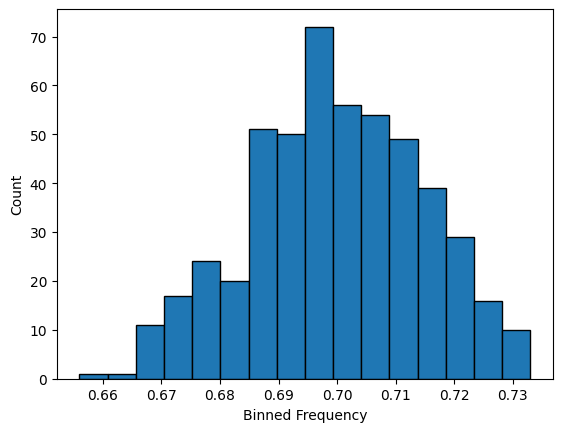

In [ ]:
# Listing 3.18 – Plotting a frequency histogram using plt.hist (Figure 3.3)
plt.hist(frequency_array, bins='auto', edgecolor='black')
plt.xlabel('Binned Frequency')
plt.ylabel('Count')
plt.show()
plt.show()

Number of Bins: 16


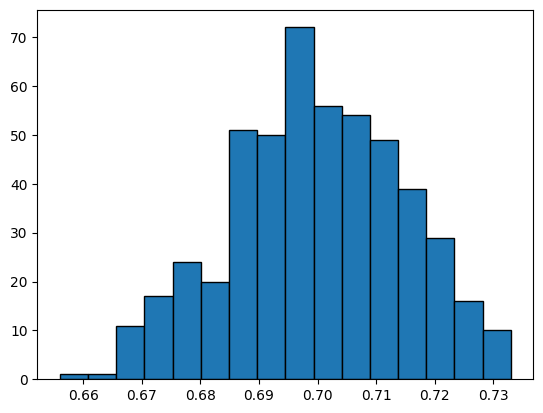

In [ ]:
# Listing 3.19 – Counting bins in a plotted histogram
counts, _, _ = plt.hist(frequency_array, bins='auto',
                        edgecolor='black')
print(f"Number of Bins: {counts.size}")

Bin width: 0.004812499999999997


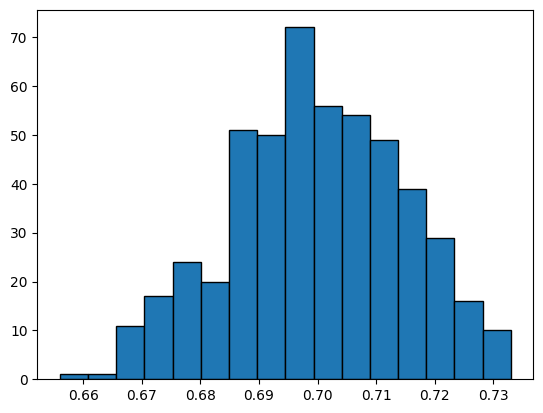

In [ ]:
# Listing 3.20 – Finding the width of bins in a histogram
counts, bin_edges, _ = plt.hist(frequency_array, bins='auto',
                                edgecolor='black')

bin_width = bin_edges[1] - bin_edges[0]
assert bin_width == (max_freq - min_freq) / counts.size
print(f"Bin width: {bin_width}")

In [ ]:
# Listing 3.21 – Getting a bin's frequency and size
def output_bin_coverage(i):
    count = int(counts[i])
    range_start, range_end = bin_edges[i], bin_edges[i+1]
    range_string = f"{range_start} - {range_end}"
    print((f"The bin for frequency range {range_string} contains "
           f"{count} element{'' if count == 1 else 's'}"))

output_bin_coverage(0)
output_bin_coverage(5)

The bin for frequency range 0.656 - 0.6608125 contains 1 element
The bin for frequency range 0.6800625 - 0.684875 contains 20 elements


In [ ]:
# Listing 3.22 – Finding the index of an array's maximum value
assert counts[counts.argmax()] == counts.max()

In [ ]:
# Listing 3.23 – Using argmax to return a histogram's peak
output_bin_coverage(counts.argmax())

The bin for frequency range 0.6945 - 0.6993125 contains 72 elements


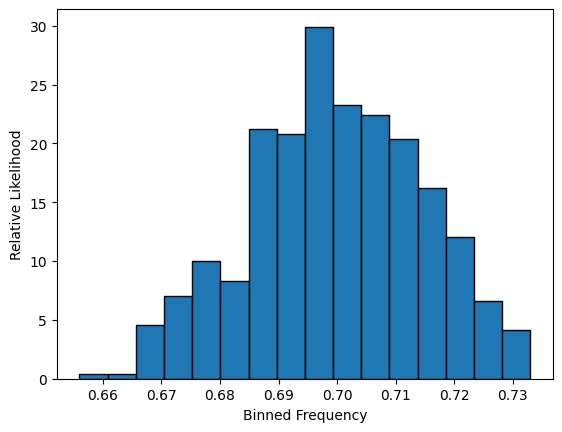

In [ ]:
# Listing 3.24 – Plotting a histogram's relative likelihoods (Figure 3.4)
likelihoods, bin_edges, _ = plt.hist(frequency_array, bins='auto',
                                     edgecolor='black', density=True)
plt.xlabel('Binned Frequency')
plt.ylabel('Relative Likelihood')
plt.show()

In [ ]:
# Listing 3.25 – Computing the total area under a histogram
assert likelihoods.sum() * bin_width == 1.0
print(likelihoods.sum() * bin_width)

1.0


In [ ]:
# Listing 3.26 – Computing the probability of the peak frequencies
index = likelihoods.argmax()
area = likelihoods[index] * bin_width
range_start, range_end = bin_edges[index], bin_edges[index+1]
range_string = f"{range_start} - {range_end}"
print(f"Sampled frequency falls within interval {range_string} with probability {area}")

Sampled frequency falls within interval 0.6945 - 0.6993125 with probability 0.144


In [ ]:
# Listing 3.27 – Increasing the probability of a frequency range
peak_index = likelihoods.argmax()
start_index, end_index = (peak_index - 1, peak_index + 2)
area = likelihoods[start_index: end_index + 1].sum() * bin_width
range_start, range_end = bin_edges[start_index], bin_edges[end_index]
range_string = f"{range_start} - {range_end}"
print(f"Sampled frequency falls within interval {range_string} with probability {area}")

Sampled frequency falls within interval 0.6896875 - 0.704125 with probability 0.464


In [ ]:
# Listing 3.28 – Computing a high confidence interval
def compute_high_confidence_interval(likelihoods, bin_width):
    peak_index = likelihoods.argmax()
    area = likelihoods[peak_index] * bin_width
    start_index, end_index = peak_index, peak_index + 1
    while area < 0.95:
        if start_index > 0:
            start_index -= 1
        if end_index < likelihoods.size - 1:
            end_index += 1

        area = likelihoods[start_index: end_index + 1].sum() * bin_width

    range_start, range_end = bin_edges[start_index], bin_edges[end_index]
    range_string = f"{range_start:.6f} - {range_end:.6f}"
    print((f"The frequency range {range_string} represents a "
           f"{100 * area:.2f}% confidence interval"))
    return start_index, end_index

compute_high_confidence_interval(likelihoods, bin_width)

The frequency range 0.670438 - 0.723375 represents a 95.40% confidence interval


(np.int64(3), np.int64(14))

7. What is the central limit theorem?
For many repeated independent observations, the distribution of sample averages or frequencies becomes approximately bell-shaped as sample size grows (under standard conditions). More observations per experiment also make the frequencies cluster closer to the true probability.

In [ ]:
# Listing 3.29 – Sampling 100,000 frequencies
np.random.seed(0)
head_count_array = np.random.binomial(1000, 0.7, 100000)
frequency_array = head_count_array / 1000
assert frequency_array.size == 100000

The frequency range 0.670429 - 0.727857 represents a 95.42% confidence interval


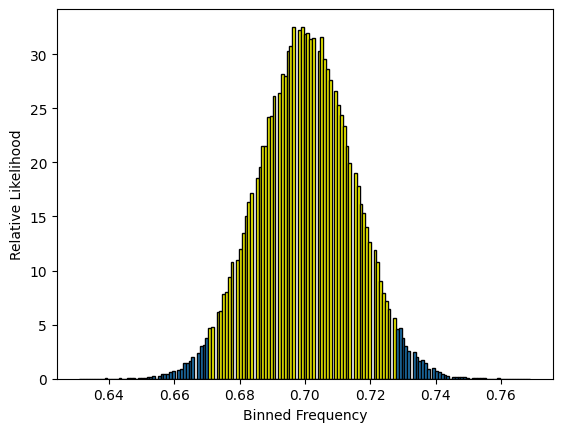

In [ ]:
# Listing 3.30 – Coloring histogram bars over an interval (Figure 3.5)
likelihoods, bin_edges, patches = plt.hist(frequency_array, bins='auto',
                                           edgecolor='black', density=True)
bin_width = bin_edges[1] - bin_edges[0]
start_index, end_index = compute_high_confidence_interval(likelihoods,
                                                          bin_width)

for i in range(start_index, end_index):
    patches[i].set_facecolor('yellow')
plt.xlabel('Binned Frequency')
plt.ylabel('Relative Likelihood')
plt.show()

The frequency range 0.695769 - 0.703708 represents a 95.06% confidence interval


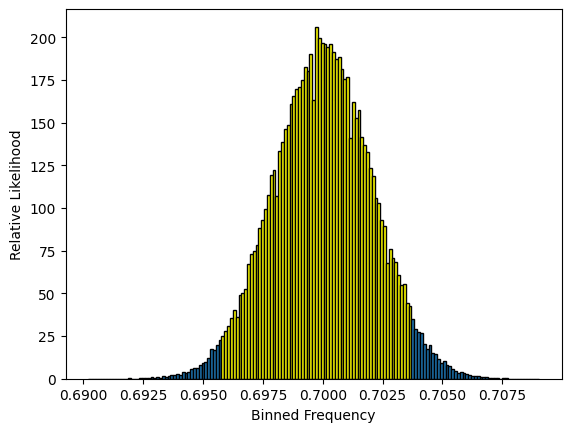

In [ ]:
# Listing 3.31 – Sampling 5 billion flipped coins (Figure 3.6)
np.random.seed(0)
head_count_array = np.random.binomial(50000, 0.7, 100000)
frequency_array = head_count_array / 50000

likelihoods, bin_edges, patches = plt.hist(frequency_array, bins='auto',
                                           edgecolor='black', density=True)
bin_width = bin_edges[1] - bin_edges[0]
start_index, end_index = compute_high_confidence_interval(likelihoods,
                                                          bin_width)

for i in range(start_index, end_index):
    patches[i].set_facecolor('yellow')
plt.xlabel('Binned Frequency')
plt.ylabel('Relative Likelihood')
plt.show()

8. Can we compute histogram parameters without drawing a plot?
Yes. We can use np.histogram() to get bin counts or densities and bin edges without making a figure.

In [ ]:
# Listing 3.32 – Computing a histogram using np.histogram (no plot)
np.random.seed(0)
likelihoods, bin_edges = np.histogram(frequency_array, bins='auto',
                                      density=True)
bin_width = bin_edges[1] - bin_edges[0]
compute_high_confidence_interval(likelihoods, bin_width)

The frequency range 0.695769 - 0.703708 represents a 95.06% confidence interval


(np.int64(47), np.int64(114))

9. How is this relevant to the card game?
We can shuffle cards many times and estimate how often we win. Histograms and intervals help us decide whether a strategy really beats 50%, instead of trusting a few lucky games.



In [ ]:
# Listing 3.33 – Generating a random red card count
np.random.seed(0)
total_cards = 52
red_card_count = np.random.randint(0, total_cards + 1)

In [ ]:
# Listing 3.34 – Generating a black card count
black_card_count = total_cards - red_card_count
assert black_card_count != red_card_count

In [ ]:
# Listing 3.35 – Computing card probabilities using a sample space
weighted_sample_space = {'red_card': red_card_count,
                         'black_card': black_card_count}
prob_red = compute_event_probability(lambda x: x == 'red_card',
                                     weighted_sample_space)

In [ ]:
# Listing 3.36 – Computing card probabilities using division
assert prob_red == red_card_count / total_cards

In [ ]:
# Listing 3.37 – Simulating a random card
np.random.seed(0)
color = 'red' if np.random.binomial(1, prob_red) else 'black'
print(f"The first card in the shuffled deck is {color}")

The first card in the shuffled deck is red


In [ ]:
# Listing 3.38 – Simulating 10 random cards
np.random.seed(0)
red_count = np.random.binomial(10, prob_red)
print(f"In {red_count} of out 10 shuffles, a red card came up first.")

In 8 of out 10 shuffles, a red card came up first.


In [ ]:
# Listing 3.39 – Computing card probability confidence intervals
np.random.seed(0)
red_card_count_array = np.random.binomial(50000, prob_red, 100000)
frequency_array = red_card_count_array / 50000

likelihoods, bin_edges = np.histogram(frequency_array, bins='auto',
                                      density=True)
bin_width = bin_edges[1] - bin_edges[0]
start_index, end_index = compute_high_confidence_interval(likelihoods,
                                                          bin_width)

The frequency range 0.842865 - 0.849139 represents a 95.16% confidence interval


In [ ]:
# Listing 3.40 – Estimating the red card count
range_start = round(0.842771 * total_cards)
range_end = round(0.849139 * total_cards)
print(f"The number of red cards in the deck is between {range_start} and {range_end}")

The number of red cards in the deck is between 44 and 44


In [ ]:
# Listing 3.41 – Validating the red card count
if red_card_count == 44:
    print('We are correct! There are 44 red cards in the deck')
else:
    print('Oops! Our sampling estimation was wrong.')

We are correct! There are 44 red cards in the deck


10. How does the chapter propose shuffling the deck?
Use np.random.shuffle(deck) to change the existing deck, or np.random.permutation(deck) to return a shuffled copy without changing the original. For every possible arrangement of a small deck, use itertools.permutations.



In [ ]:
# Listing 3.42 – Shuffling a four-card deck
np.random.seed(0)
card_deck = [1, 1, 0, 0]
np.random.shuffle(card_deck)
print(card_deck)

[0, 0, 1, 1]


In [ ]:
# Listing 3.43 – Returning a copy of the shuffled deck
np.random.seed(0)
unshuffled_deck = [1, 1, 0, 0]
shuffled_deck = np.random.permutation(unshuffled_deck)
assert unshuffled_deck == [1, 1, 0, 0]
print(shuffled_deck)

[0 0 1 1]


In [ ]:
# Listing 3.44 – Iterating over card permutations
import itertools
for permutation in list(itertools.permutations(unshuffled_deck))[:3]:
    print(permutation)

(1, 1, 0, 0)
(1, 1, 0, 0)
(1, 0, 1, 0)


In [ ]:
# Listing 3.45 – Monitoring permutation swaps
for permutation in list(itertools.permutations([0, 1, 2, 3]))[:3]:
    print(permutation)

(0, 1, 2, 3)
(0, 1, 3, 2)
(0, 2, 1, 3)


In [ ]:
# Listing 3.46 – Computing permutation counts
weighted_sample_space = defaultdict(int)
for permutation in itertools.permutations(unshuffled_deck):
    weighted_sample_space[permutation] += 1

for permutation, count in weighted_sample_space.items():
    print(f"Permutation {permutation} occurs {count} times")

Permutation (1, 1, 0, 0) occurs 4 times
Permutation (1, 0, 1, 0) occurs 4 times
Permutation (1, 0, 0, 1) occurs 4 times
Permutation (0, 1, 1, 0) occurs 4 times
Permutation (0, 1, 0, 1) occurs 4 times
Permutation (0, 0, 1, 1) occurs 4 times


In [ ]:
# Listing 3.47 – Computing permutation probabilities
sample_space = set(itertools.permutations(unshuffled_deck))
event_condition = lambda x: list(x) == unshuffled_deck
prob = compute_event_probability(event_condition, sample_space)
assert prob == 1 / len(sample_space)
print(f"Probability that a shuffle does not alter the deck is {prob}")

Probability that a shuffle does not alter the deck is 0.16666666666666666


11. Why do we work with a 10-card deck?
A 52-card deck has far too many possible red/black arrangements to check one by one. A 10-card deck with 5 red and 5 black cards has only 252 distinct color arrangements, so we can examine them all.

In [ ]:
# Listing 3.48 – Computing a 10-card sample space
red_cards = 5 * [1]
black_cards = 5 * [0]
unshuffled_deck = red_cards + black_cards
sample_space = set(itertools.permutations(unshuffled_deck))
print(f"Sample space for a 10-card deck contains {len(sample_space)} elements")

Sample space for a 10-card deck contains 252 elements


Chapter 3 conclusion
I learned how to simulate random events, make histograms, estimate probabilities, and use confidence intervals. These tools prepare us to test the card-game strategy in Chapter 4.